# I ACCEPT THE HONOUR CODE

# Imports

In [2]:
import math
import numpy as np
from scipy.stats import binom
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt

# Helper Functions

In [3]:
#Function to noise variance for a given epsilon

def sigma_squared(epsilon, delta=1e-6):
    return 2 * math.log(1.25 / delta) / (epsilon ** 2)

In [4]:
#Samples m random vectors sampled uniformly from the unit sphere in R^d.

def sample_unit_vectors(m, d):
    
    X = np.random.randn(m, d)

    X = X / np.linalg.norm(X, axis=1, keepdims=True)

    return X

In [5]:
# Score function

def row_dot_products(theta, D_canary):

    return (D_canary @ theta).tolist()

In [6]:
# Randomised algorithm to audit

def private_algo(D, sigma_squared):

    A_D = np.sum(D, axis=0)
    d = A_D.shape[0]

    noise = np.random.normal(
        loc=0,
        scale=np.sqrt(sigma_squared),
        size=d
    )

    return A_D + noise

In [7]:
# Splits rows of D into D_plus and D_minus

def split_dataset(D):

    m = D.shape[0]

    # m number of Rademacher variables
    S = np.random.choice([-1, 1], size=m)

    D_plus = D[S == 1]
    D_minus = D[S == -1]

    return D_plus, D_minus, S

In [8]:
# Guess using the list of scores

def threshold_labels(L, m1, m2):

    L = np.array(L)
    m = len(L)

    output = np.zeros(m, dtype=int)

    smallest_idx = np.argsort(L)[:m2]

    largest_idx = np.argsort(L)[-m1:]

    output[smallest_idx] = -1
    output[largest_idx] = 1

    return output.tolist()

In [9]:
# Correct guesses and total guesses

def compute_counts(S, T):

    N_correct = sum(1 for s, t in zip(S, T) if s == t)

    N_total = sum(1 for t in T if t != 0)

    return N_correct, N_total

In [10]:
def epsilon_cap(N_total, N_correct):

    def tail_prob(eps):

        p = np.exp(eps) / (1 + np.exp(eps))

        return binom.sf(N_correct - 1, N_total, p)

    # We maximize eps while enforcing tail_prob <= 0.05
    def objective(eps):

        prob = tail_prob(eps)

        # feasible region
        if prob <= 0.05:
            return -eps

        # heavy penalty outside feasible region
        return 1e6 + prob

    result = minimize_scalar(
        objective,
        bounds=(-50, 50),
        method='bounded'
    )

    return result.x

# Question 1.1

In [11]:
# Initialising parameters

d = int (1e4)
m = int (1e3)
D = np.zeros((1, int(d)))
epsilon_values = [1, 2, 4, 8, 16]

In [12]:
epsilon_cap_values = []

for epsilon in epsilon_values:

    print (f"Processing epsilon = {epsilon}...")

    sigma2 = sigma_squared(epsilon)

    print (f"Sigma^2 = {sigma2}")

    D_canary = sample_unit_vectors(m, d)

    D_plus, D_minus, S = split_dataset(D_canary)

    D_dash = np.vstack((D, D_plus))

    theta = private_algo(D_dash, sigma2)

    scores = row_dot_products(theta, D_canary)

    epsilon_lower_bounds = []

    for m1 in range(1, min(m // 2, 500) + 1):

        T = threshold_labels(scores, m1, m1)

        N_correct, N_total = compute_counts(S, T)

        epsilon_lower_bound = epsilon_cap(N_total, N_correct)

        print (f"m1 = {m1}, N_correct = {N_correct}, N_total = {N_total}, epsilon_lower_bound = {epsilon_lower_bound}")

        epsilon_lower_bounds.append(epsilon_lower_bound)

    largest_epsilon_lower_bound = max(epsilon_lower_bounds)

    epsilon_cap_values.append(largest_epsilon_lower_bound)



Processing epsilon = 1...
Sigma^2 = 28.07730821855697
m1 = 1, N_correct = 2, N_total = 2, epsilon_lower_bound = -1.2447712131607191
m1 = 2, N_correct = 3, N_total = 4, epsilon_lower_bound = -1.1060701326475553
m1 = 3, N_correct = 5, N_total = 6, epsilon_lower_bound = -0.3301854379345808
m1 = 4, N_correct = 6, N_total = 8, epsilon_lower_bound = -0.40417404953164937
m1 = 5, N_correct = 7, N_total = 10, epsilon_lower_bound = -0.43314523463500537
m1 = 6, N_correct = 8, N_total = 12, epsilon_lower_bound = -0.44369300695060565
m1 = 7, N_correct = 9, N_total = 14, epsilon_lower_bound = -0.4455727349747243
m1 = 8, N_correct = 10, N_total = 16, epsilon_lower_bound = -0.44306370211219664
m1 = 9, N_correct = 11, N_total = 18, epsilon_lower_bound = -0.43826179458320325
m1 = 10, N_correct = 13, N_total = 20, epsilon_lower_bound = -0.23318949755260054
m1 = 11, N_correct = 15, N_total = 22, epsilon_lower_bound = -0.06184888853752663
m1 = 12, N_correct = 16, N_total = 24, epsilon_lower_bound = -0.0857

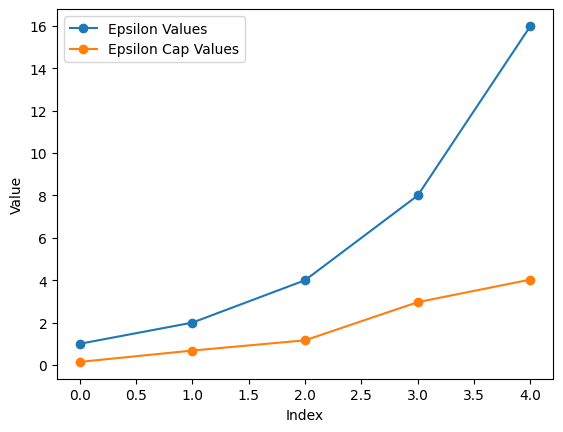

In [13]:
# Plotting

x = range(len(epsilon_values))

plt.plot(x, epsilon_values, label="Epsilon Values", marker='o')
plt.plot(x, epsilon_cap_values, label="Epsilon Cap Values", marker='o')

plt.xlabel("Index")
plt.ylabel("Value")

plt.legend()

plt.show()

As expected, the algorithm provides a valid lower bound for the actual epsilon value, although rarely, the estimated lower bound for epsilon overshoots the actual epsilon value. 

This is because, the lower bound we obtain via the algorithm holds with a probability of 0.95, which leaves us with a failure probability of 0.05.

# Question 1.2

In [14]:
# Initialising parameters

d = int (1e4)
D = np.zeros((1, int(d)))
epsilon_values = 16
sigma2 = sigma_squared(epsilon)
m_values = [2**6, 2**8, 2**10, 2**12, 2**14]

In [15]:
epsilon_cap_values = []

for m in m_values:

    print (f"Processing m = {m}...")

    D_canary = sample_unit_vectors(m, d)

    D_plus, D_minus, S = split_dataset(D_canary)

    D_dash = np.vstack((D, D_plus))

    theta = private_algo(D_dash, sigma2)

    scores = row_dot_products(theta, D_canary)

    epsilon_lower_bounds = []

    for m1 in range(1, min(m // 2, 500) + 1):

        T = threshold_labels(scores, m1, m1)

        N_correct, N_total = compute_counts(S, T)

        epsilon_lower_bound = epsilon_cap(N_total, N_correct)

        print (f"m1 = {m1}, N_correct = {N_correct}, N_total = {N_total}, epsilon_lower_bound = {epsilon_lower_bound}")

        epsilon_lower_bounds.append(epsilon_lower_bound)

    largest_epsilon_lower_bound = max(epsilon_lower_bounds)

    epsilon_cap_values.append(largest_epsilon_lower_bound)



Processing m = 64...
m1 = 1, N_correct = 2, N_total = 2, epsilon_lower_bound = -1.2447712131607191
m1 = 2, N_correct = 4, N_total = 4, epsilon_lower_bound = -0.10862503791206023
m1 = 3, N_correct = 6, N_total = 6, epsilon_lower_bound = 0.4345605893599159
m1 = 4, N_correct = 8, N_total = 8, epsilon_lower_bound = 0.7891792183844241
m1 = 5, N_correct = 10, N_total = 10, epsilon_lower_bound = 1.0518725584424005
m1 = 6, N_correct = 12, N_total = 12, epsilon_lower_bound = 1.2602981803811015
m1 = 7, N_correct = 14, N_total = 14, epsilon_lower_bound = 1.4329701864720632
m1 = 8, N_correct = 16, N_total = 16, epsilon_lower_bound = 1.5803184335647353
m1 = 9, N_correct = 18, N_total = 18, epsilon_lower_bound = 1.708810639635205
m1 = 10, N_correct = 20, N_total = 20, epsilon_lower_bound = 1.8227119886688952
m1 = 11, N_correct = 22, N_total = 22, epsilon_lower_bound = 1.92499357954682
m1 = 12, N_correct = 24, N_total = 24, epsilon_lower_bound = 2.017804230185298
m1 = 13, N_correct = 26, N_total = 26

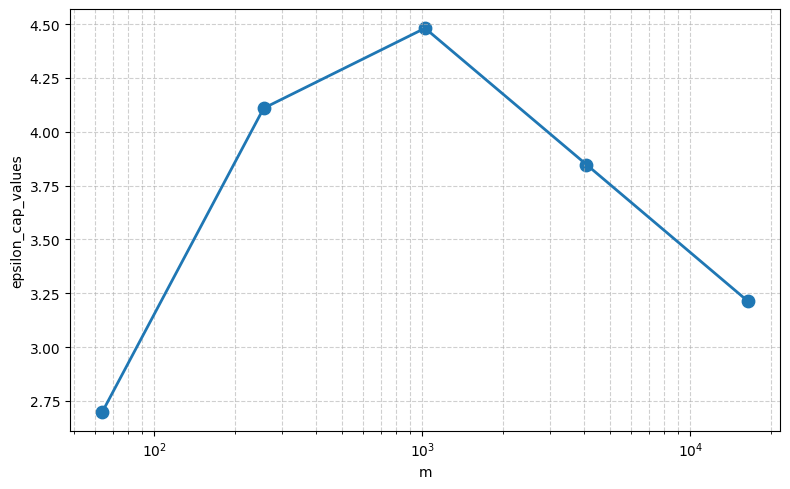

In [16]:
# Plotting
x = m_values
y = epsilon_cap_values

plt.figure(figsize=(8, 5))

plt.plot(
    x,
    y,
    linewidth=2,
    label="Epsilon cap"
)

plt.scatter(
    x,
    y,
    s=80
)

plt.xscale('log')

plt.xlabel("m")
plt.ylabel("epsilon_cap_values")

plt.grid(True, which="both", linestyle="--", alpha=0.6)

plt.tight_layout()

plt.show()

Trend: As m increases, initially the estimated epsilon lower biound gets close to its actual value, but soon the tightness of the lower bound reduces.

This is because, with more number of canaries, the number of membership inference attacks we run increases, due to which we would expect the estimated lower bound to always get tighter as m increaes.

However, as the number of canary points increase, the signal to noise ratio in our score function reduces (since for finite d, random vectors need not be orthogonal). Hence, the membership inference attacks start to get inaccurate as m increases a lot.

# Question 1.3

In [17]:
# Initialising parameters

m = int(1e3)
epsilon_values = 16
sigma2 = sigma_squared(epsilon)
d_values = [10, 10**2, 10**3, 10**4, 10**5]

In [18]:
epsilon_cap_values = []

for d in d_values:

    print (f"Processing d = {d}...")

    D = np.zeros((1, int(d)))

    D_canary = sample_unit_vectors(m, d)

    D_plus, D_minus, S = split_dataset(D_canary)

    D_dash = np.vstack((D, D_plus))

    theta = private_algo(D_dash, sigma2)

    scores = row_dot_products(theta, D_canary)

    epsilon_lower_bounds = []

    for m1 in range(1, min(m // 2, 500) + 1):

        T = threshold_labels(scores, m1, m1)

        N_correct, N_total = compute_counts(S, T)

        epsilon_lower_bound = epsilon_cap(N_total, N_correct)

        print (f"m1 = {m1}, N_correct = {N_correct}, N_total = {N_total}, epsilon_lower_bound = {epsilon_lower_bound}")

        epsilon_lower_bounds.append(epsilon_lower_bound)

    largest_epsilon_lower_bound = max(epsilon_lower_bounds)

    epsilon_cap_values.append(largest_epsilon_lower_bound)



Processing d = 10...
m1 = 1, N_correct = 1, N_total = 2, epsilon_lower_bound = -3.650493861447489
m1 = 2, N_correct = 3, N_total = 4, epsilon_lower_bound = -1.1060701326475553
m1 = 3, N_correct = 4, N_total = 6, epsilon_lower_bound = -0.9878442759067952
m1 = 4, N_correct = 5, N_total = 8, epsilon_lower_bound = -0.8990782022419173
m1 = 5, N_correct = 7, N_total = 10, epsilon_lower_bound = -0.43314523463500537
m1 = 6, N_correct = 8, N_total = 12, epsilon_lower_bound = -0.44369300695060565
m1 = 7, N_correct = 8, N_total = 14, epsilon_lower_bound = -0.7307594356775536
m1 = 8, N_correct = 10, N_total = 16, epsilon_lower_bound = -0.44306370211219664
m1 = 9, N_correct = 12, N_total = 18, epsilon_lower_bound = -0.21703358195822348
m1 = 10, N_correct = 12, N_total = 20, epsilon_lower_bound = -0.4322722169925929
m1 = 11, N_correct = 12, N_total = 22, epsilon_lower_bound = -0.6078757362330067
m1 = 12, N_correct = 14, N_total = 24, epsilon_lower_bound = -0.41888173589016114
m1 = 13, N_correct = 15

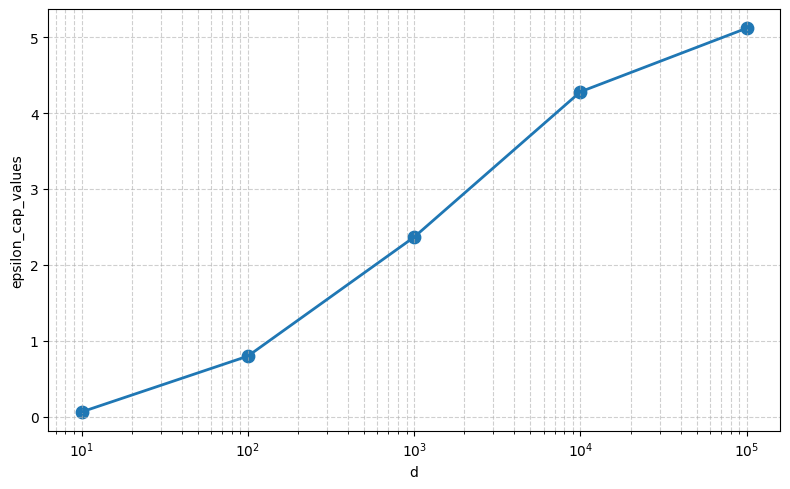

In [19]:
# Plotting

x = d_values
y = epsilon_cap_values

plt.figure(figsize=(8, 5))

plt.plot(
    x,
    y,
    linewidth=2,
    label="Epsilon cap"
)

plt.scatter(
    x,
    y,
    s=80
)

plt.xscale('log')

plt.xlabel("d")
plt.ylabel("epsilon_cap_values")

plt.grid(True, which="both", linestyle="--", alpha=0.6)

plt.tight_layout()

plt.show()

Trend: As d increases, the tightness of the lower bound on epsilon that we obtain increases.

The membership inference attacks get more accurate with the increase in d as the tendency of random vectors being orthogonal to one another increases as d increases. Due to this, for a given value of N_total, as d is increased, the value of N_correct increases which in turn causes the value of our algorithms estimated lower bound on epsilon to increase.